# Streamlines from Delft3D-FM simulations
This notebook generates a streamlines plot and animation to show the velocity field. The animation is fixed at a single timestep (which can be selected).

### Load libraries

In [3]:
import os
import re
import filecmp
import datetime
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from tkinter import Tk, filedialog
from scipy.interpolate import griddata
from pyproj import Transformer
from scipy.interpolate import griddata, RegularGridInterpolator

# packages for Delft3D FM 
import hydrolib.core.dflowfm as hcdfm
import dfm_tools as dfmt

# Plotting stuff
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['axes.titlesize'] = 14  # Title size
matplotlib.rcParams['axes.labelsize'] = 13  # Axis label size
matplotlib.rcParams['xtick.labelsize'] = 12  # X tick labels size
matplotlib.rcParams['ytick.labelsize'] = 12  # Y tick labels size
matplotlib.rcParams['legend.fontsize'] = 12  # Legend label size

import matplotlib.pyplot as plt
from cmcrameri import cm
import matplotlib.animation as animation
from matplotlib.collections import LineCollection
import matplotlib.ticker as ticker 
from mpl_toolkits.axes_grid1 import make_axes_locatable

### Load simulation
The script opens up a window that allows to navigate to the simulation folder. It creates a new folder (within the simulation folder) named $\texttt{post\_processing}$ where everything is saved. The script assumes that the simulation was run in DIMR configuration, and looks for the $\texttt{dflowfm}$ folder with the subfolder $\texttt{output}$ where the output are saved.

In [2]:
root = Tk()
root.withdraw()
root.attributes('-topmost', True)

# Ask the folder
folder_path  = filedialog.askdirectory(title="Select simulation directory")
root.destroy()

if folder_path:
    print("---> Selected folder:", folder_path)
          
    # Create a folder where we save the figures and other post-processing stuff
    output_folder = os.path.join(folder_path, 'post_processing')
    os.makedirs(output_folder, exist_ok = True)
else:
    print("No folder selected.")

# Read the FlowFM_map.nc file
map_netcdf = os.path.join(folder_path, "dflowfm", "output", 'FlowFM_*_map.nc')
print("---> Reading:", map_netcdf)
map_xr = dfmt.open_partitioned_dataset(map_netcdf)

---> Selected folder: C:/Users/cortel/Desktop/Lake_Seminole_model/8_1_hydro_weir/weir_downstream
---> Reading: C:/Users/cortel/Desktop/Lake_Seminole_model/8_1_hydro_weir/weir_downstream\dflowfm\output\FlowFM_*_map.nc
>> xu.open_dataset() with 8 partition(s): 1 2 3 4 5 6 7 8 : 1.36 sec
>> xu.merge_partitions() with 8 partition(s): 0.72 sec
>> dfmt.open_partitioned_dataset() total: 2.09 sec


### Static streamlines plot (domain)
This cell produces a static plot (i.e., the lines do not move) of the streamlines. It can be very helpful to set up the animation and choose the right parameters.

Selected time: 2023-10-10 08:00
>> rasterizing ugrid Dataset with 2 face variables to shape=(1802,2807): 1.43 sec


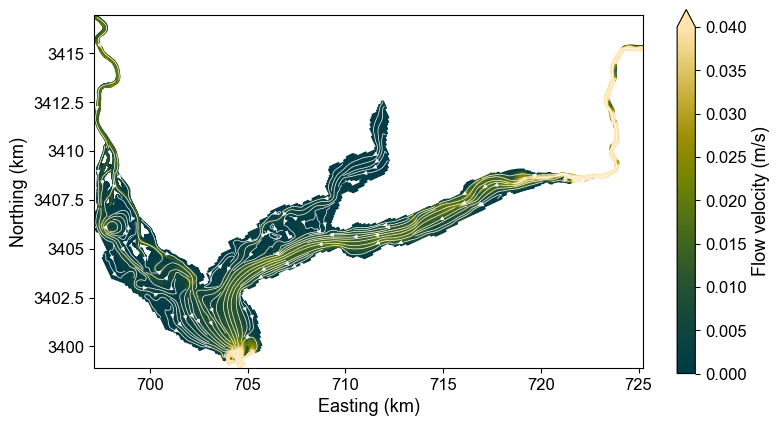

In [36]:
# ================ USER INPUTS ======================
target_t       = 57    # timestep to plot
rasterize_res  = 10    # raster resolution for streamlines
cbar_min       = 0.00  # min value for background map
cbar_max       = 0.04  # max value for background map
colormap       = cm.bamako
colormap_label = 'Flow velocity (m/s)'

# Streamlines parameters
streamlines_density    = 7
streamlines_width      = 0.5
streamlines_arrow_size = 0.6
# ====================================================

# Extract simulation at the targeted time
uds_t = map_xr.isel(time=target_t)

# Show selected time
selected_time = uds_t.time.values
formatted_time = pd.to_datetime(selected_time).strftime('%Y-%m-%d %H:%M')
print(f"Selected time: {formatted_time}")

# Compute velocity magnitude and set it to 0 where depth=0.
mag_data = np.sqrt(uds_t['mesh2d_ucx']**2 + uds_t['mesh2d_ucy']**2)
uds_t['magn'] = mag_data.where(uds_t['mesh2d_waterdepth'] != 0, np.nan).load()

# Rasterize the map because we need a regular grid 
raster_uv = dfmt.rasterize_ugrid(uds_t[['mesh2d_ucx', 'mesh2d_ucy']], resolution=rasterize_res).load()

# Extract the new grid dimensions
x_1d = raster_uv['x'].values
y_1d = raster_uv['y'].values
U_2d = raster_uv['mesh2d_ucx'].values
V_2d = raster_uv['mesh2d_ucy'].values

# Set y coordinates in increasing order
if y_1d[0] > y_1d[-1]:
    y_1d = np.flip(y_1d)
    U_2d = np.flip(U_2d, axis=0)
    V_2d = np.flip(V_2d, axis=0)

# Build regular grid
X, Y = np.meshgrid(x_1d, y_1d)

# COMPUTE VORTICITY
dU_dy, dU_dx = np.gradient(U_2d, rasterize_res, rasterize_res)
dV_dy, dV_dx = np.gradient(V_2d, rasterize_res, rasterize_res)
vorticity_2d = dV_dx - dU_dy

# Static map
fig, ax = plt.subplots(figsize=(8, 5))

# Magnitude
poly_plot = uds_t['magn'].ugrid.plot(ax=ax, cmap=colormap, vmin=cbar_min, vmax=cbar_max, add_colorbar=True, 
                                     cbar_kwargs={'label': colormap_label,'shrink': 0.8})

# Streamlines
ax.streamplot(X, Y, U_2d, V_2d, color='white', density=streamlines_density, linewidth=streamlines_width, arrowsize=streamlines_arrow_size)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/1000:g}"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{y/1000:g}"))
ax.set_xlabel('Easting (km)')#, fontweight = "bold")
ax.set_ylabel('Northing (km)')#, fontweight = "bold")
ax.set_aspect('equal')
#ax.set_title("Streamlines at {formatted_time}", fontweight='bold')
ax.set_title("")

plt.tight_layout()

# Save and show
# PNG
output_file = os.path.join(output_folder, f"streamline_static.png")
#plt.savefig(output_file, dpi=300, bbox_inches='tight')
# EPS
output_file = os.path.join(output_folder, f"streamline_static.eps")
#plt.savefig(output_file, bbox_inches='tight', format='eps')

plt.show()

### Static streamlines plot (zoom)
Same plot as above, but zoomed on a selected area

>> rasterizing ugrid Dataset with 2 face variables to shape=(3604,5613): 8.98 sec


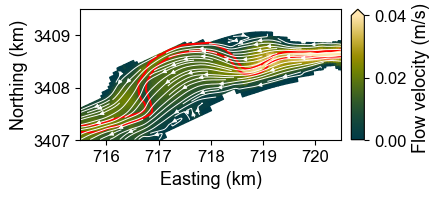

In [9]:
# ================ USER INPUTS ======================
target_t       = 57    # timestep to plot
rasterize_res  = 5     # raster resolution for streamlines

# Chatta
#lon_min, lon_max = 697000, 703000
#lat_min, lat_max = 3402000, 3405000

# Flint
lon_min, lon_max = 715500, 720500
lat_min, lat_max = 3407000, 3409500

cbar_min       = 0.00   # min value for background map
cbar_max       = 0.04   # max value for background map
colormap       = cm.bamako
colormap_label = 'Flow velocity (m/s)'

# Streamlines parameters
streamlines_density    = 1.8
streamlines_width      = 0.7
streamlines_arrow_size = 0.6
streamlines_color      = 'w'

# shapefile
paleo_channels_shp = 'paleochannels.shp'

save_filename = f"streamline_zoom_{target_t}_flint"
# ====================================================

# Extract simulation at the targeted time
uds_t = map_xr.isel(time=target_t)

# Compute velocity magnitude and set it to 0 where depth=0
mag_data = np.sqrt(uds_t['mesh2d_ucx']**2 + uds_t['mesh2d_ucy']**2)
uds_t['magn'] = mag_data.where(uds_t['mesh2d_waterdepth'] != 0, np.nan).load()

# Rasterize the map 
raster_uv = dfmt.rasterize_ugrid(uds_t[['mesh2d_ucx', 'mesh2d_ucy']], resolution=rasterize_res).load()

# Sort coordinates to strictly increasing, then crop the raster 
raster_uv = raster_uv.sortby('x').sortby('y')
raster_zoom = raster_uv.sel(x=slice(lon_min, lon_max), y=slice(lat_min, lat_max))

# Extract the newly cropped grid dimensions safely
x_1d = raster_zoom['x'].values
y_1d = raster_zoom['y'].values
U_2d = raster_zoom['mesh2d_ucx'].values
V_2d = raster_zoom['mesh2d_ucy'].values

# Build regular grid for the zoomed area
X, Y = np.meshgrid(x_1d, y_1d)

# Load the shapefile to show the paleochannel
gdf_paleochannel = gpd.read_file(paleo_channels_shp)

# Plot
fig, ax = plt.subplots(figsize=(4.5, 3))

poly_plot = uds_t['magn'].ugrid.plot(ax=ax, cmap=colormap, vmin=cbar_min, vmax=cbar_max, add_colorbar=False)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(poly_plot, cax=cax, extend='max')
cbar.ax.set_ylabel(colormap_label)

# Streamlines
ax.streamplot(X, Y, U_2d, V_2d, color=streamlines_color, 
              density=streamlines_density, linewidth=streamlines_width, 
              arrowsize=streamlines_arrow_size)

gdf_paleochannel.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1.5, linestyle='-')

# Apply the visual zoom to the axes
ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# Formatting
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/1000:g}"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{y/1000:g}"))
ax.set_xlabel('Easting (km)')
ax.set_ylabel('Northing (km)')
ax.set_aspect('equal')
ax.set_title("")

plt.tight_layout()

output_png = os.path.join(output_folder, f"{save_filename}.png")
output_eps = os.path.join(output_folder, f"{save_filename}.eps")

plt.savefig(output_png, dpi=300, bbox_inches='tight')
plt.savefig(output_eps, bbox_inches='tight', format='eps')

plt.show()

### Streamlines animation
This cell produces the streamline animation. The goal here is to produce a simple animation similar to the [$\texttt{ipyleaflet}$](https://ipyleaflet.readthedocs.io/en/latest/layers/velocity.html) library.

The scripts prepares and interpolates velocity like the script above. IMPORTANT: the calculation of the streamlines is done using the [$\texttt{streamplot}$](https://github.com/matplotlib/matplotlib/blob/main/lib/matplotlib/streamplot.py) function, but in this function the streamlines are set as invisible. We use it just to calculate the geometric lines ($\texttt{raw\_segments}$). If you need to export the streamlines, export the $\texttt{raw\_segments}$, which has the coordinates defining each line. 

The script averages the velocity along the streamlines and group the lines into tiers ($\texttt{bins}$). To get the fading tail effect, the script ovelaps multiple copies of the steamlines with each layers getting progressively more transparent

In [23]:
# ================ USER INPUTS ======================
target_t       = 50   # timestep to plot
rasterize_res  = 10   # raster resolution for streamlines
cbar_min       = 0.0  # min value for plot
cbar_max       = 0.04 # max value for plot
colormap       = cm.bamako
colormap_label = 'Flow velocity (m/s)'

# Streamlines parameters
streamlines_density    = 7.5 # the higher the denser the lines
streamlines_width      = 0.5 # thickness of the lines

# Tail settings <- this is the part where we define the esthetic of the moving particles
particle_color  = 'white'
num_layers      = 40   # Segments making up the tail
segment_length  = 3    # Base length of the individual ink dash
gap_length      = 100  # Base gap so they look like particles
fade_max        = 1    # Fading max parameter (1= fully visible)
fade_min        = 0    # Fading min parameter

# Animation
particle_speed  = 2.0  # Base speed multiplier for the animation
num_speed_tiers = 5    # Number of speed bins to group particles into
# ====================================================

fig, ax = plt.subplots(figsize=(8, 5))

uds_t = map_xr.isel(time=target_t)

# Selected time
selected_time = uds_t.time.values
formatted_time = pd.to_datetime(selected_time).strftime('%Y-%m-%d %H:%M')
print(f"Selected time: {formatted_time}")

# Compute velocity (velocity=0 where depth=0)
mag_data = np.sqrt(uds_t['mesh2d_ucx']**2 + uds_t['mesh2d_ucy']**2)
uds_t['magn'] = mag_data.where(uds_t['mesh2d_waterdepth'] != 0, np.nan)
poly_plot = uds_t['magn'].ugrid.plot(ax=ax, cmap=colormap, vmin=cbar_min, vmax=cbar_max, add_colorbar=True, 
                                     cbar_kwargs={'label': colormap_label,'shrink': 0.8})

# Rasterize the map like before
raster_uv = dfmt.rasterize_ugrid(uds_t[['mesh2d_ucx', 'mesh2d_ucy']], resolution=rasterize_res).load()

# Extract the new grid dimensions
x_1d = raster_uv['x'].values
y_1d = raster_uv['y'].values
U_2d = raster_uv['mesh2d_ucx'].values
V_2d = raster_uv['mesh2d_ucy'].values

# Set y coordinates in increasing order
if y_1d[0] > y_1d[-1]:
    y_1d = np.flip(y_1d)
    U_2d = np.flip(U_2d, axis=0)
    V_2d = np.flip(V_2d, axis=0)

# # Set x coordinates in increasing order
if x_1d[0] > x_1d[-1]:
    x_1d = np.flip(x_1d)
    U_2d = np.flip(U_2d, axis=1)
    V_2d = np.flip(V_2d, axis=1)
    
# Build regular grid and calculate magnitude
X, Y = np.meshgrid(x_1d, y_1d)
magnitude_grid = np.sqrt(U_2d**2 + V_2d**2)

# Streamlines
stream = ax.streamplot(X, Y, U_2d, V_2d, color='none', density=streamlines_density, linewidth=streamlines_width)

# Extract the raw, continuous multi-point segments
raw_segments = stream.lines.get_segments()

# Interpolation
interp = RegularGridInterpolator((y_1d, x_1d), magnitude_grid, bounds_error=False, fill_value=0)

segment_speeds = []
valid_segments = []

for line in raw_segments:
    if len(line) < 2:
        continue
        
    # line[:, 1] is Y, line[:, 0] is X
    # Interpolate velocities at every point along the continuous path
    pts_speed = interp(np.column_stack((line[:, 1], line[:, 0])))
    
    # Average the speeds to determine how fast particles should move on this line
    avg_speed = np.nanmean(pts_speed)
    
    segment_speeds.append(avg_speed)
    valid_segments.append(line)

segment_speeds = np.array(segment_speeds)

# Group the segments into speed "bins" (tiers)
min_spd, max_spd = np.nanmin(segment_speeds), np.nanmax(segment_speeds)
bins = np.linspace(min_spd, max_spd, num_speed_tiers + 1)
bin_indices = np.digitize(segment_speeds, bins) - 1
bin_indices = np.clip(bin_indices, 0, num_speed_tiers - 1)

# build individual layers per speed tier
alphas = np.linspace(fade_max, fade_min, num_layers) ** 2
tiered_layers = []       
tier_scales = []     

for tier in range(num_speed_tiers):
    # Use list comprehension to filter the continuous segments by tier
    tier_segs = [valid_segments[i] for i in range(len(valid_segments)) if bin_indices[i] == tier]
    
    if len(tier_segs) == 0:
        continue

    # Create a multiplier (e.g., 0.2 up to 1.0) based on the tier
    # Particle that move faster have higher multiplier
    scale_factor = (tier + 1) / num_speed_tiers
    
    tier_layer_group = []
    for i in range(num_layers):
        lc = LineCollection(tier_segs, colors=particle_color, linewidths=streamlines_width, alpha=alphas[i])
        ax.add_collection(lc)
        tier_layer_group.append(lc)

    tiered_layers.append(tier_layer_group)
    tier_scales.append(scale_factor)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/1000:g}"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{y/1000:g}"))
ax.set_xlabel('Easting (km)')#, fontweight = "bold")
ax.set_ylabel('Northing (km)')#, fontweight = "bold")
ax.set_aspect('equal')
ax.set_title('')

# Animation function
def animate(i):
    updated_collections = []
    
    for tier_group, scale in zip(tiered_layers, tier_scales):
        # physical length and visual velocity based on the tier
        local_speed  = particle_speed * scale
        local_seg    = segment_length * scale
        local_gap    = gap_length * scale
        
        base_offset = -i * local_speed  
        
        for j, lc in enumerate(tier_group):
            layer_offset = base_offset + (j * local_seg)
            lc.set_linestyle((layer_offset, (local_seg, local_gap)))
            updated_collections.append(lc)
            
    return updated_collections

# Render animation and save
ani = animation.FuncAnimation(fig, animate, frames=300, interval=50, blit=True)

output_video = os.path.join(output_folder, "streamlines.mp4")
#ani.save(output_video, dpi=200, writer='ffmpeg')

plt.close(fig)

Selected time: 2023-10-10 01:00
>> rasterizing ugrid Dataset with 2 face variables to shape=(1802,2807): 1.22 sec



KeyboardInterrupt


KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x000002357451DD00> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x00000235B5A8CB80> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 